# Treino: previsão do USD/BRL (D+1)

Série univariada: fechamento diário de `BRL=X` (reais por 1 dólar). Alvo: fechamento do dia seguinte.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

d:\Repositories\dolar-predictor-docker\.venv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
TICKER = "BRL=X"
START = "2015-01-01"

# o notebook roda de dentro de notebooks/; os caminhos apontam para a raiz do repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)
RAW_CSV = DATA_DIR / "brl_x.csv"

## Coleta

Baixa do Yahoo e salva em CSV. Se o download falhar (sem internet), usa o CSV salvo antes.

In [3]:
try:
    raw = yf.download(TICKER, start=START, interval="1d", auto_adjust=False, progress=False)
    if raw.empty:
        raise ValueError("download vazio")
    # yfinance 1.x devolve colunas MultiIndex (campo, ticker)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    df = raw[["Close"]].rename(columns={"Close": "close"}).dropna()
    df.index.name = "date"
    df.to_csv(RAW_CSV)
    print("baixado do Yahoo")
except Exception as e:
    print(f"download falhou ({e}); lendo {RAW_CSV}")
    df = pd.read_csv(RAW_CSV, index_col="date", parse_dates=True)

print(df.shape)
print(df.index.min().date(), "->", df.index.max().date())
df.tail()

baixado do Yahoo
(3060, 1)
2015-01-01 -> 2026-10-05


Price,close
date,
2026-09-29,5.2229
2026-09-30,5.2029
2026-10-01,5.1791
2026-10-02,5.2226
2026-10-05,4.9970


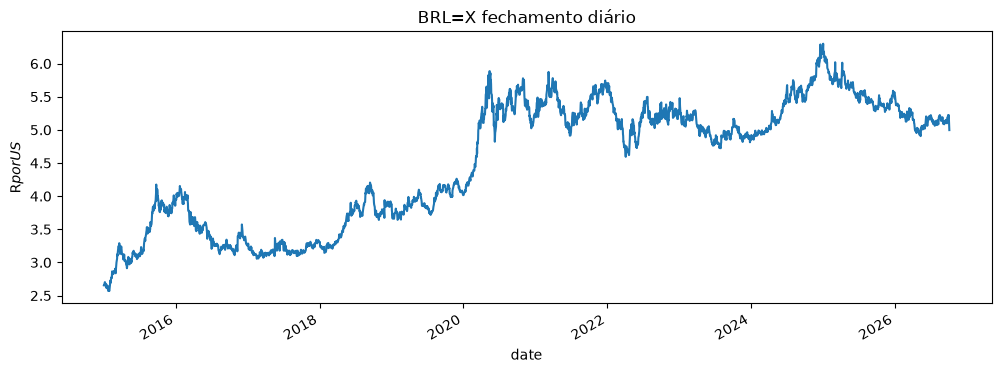

In [4]:
ax = df["close"].plot(figsize=(12, 4), title=f"{TICKER} fechamento diário")
ax.set_ylabel(r"R\$ por US\$")
plt.show()

## Remover o candle de hoje

Durante o pregão o Yahoo devolve o dia corrente com a cotação parcial. Esse valor ainda vai mudar, então fica fora do treino e da avaliação.

In [5]:
hoje = pd.Timestamp.today().normalize()
print("linhas com data >= hoje:", (df.index >= hoje).sum())
print(df[df.index >= hoje])
df = df[df.index < hoje]
print(df.index.min().date(), "->", df.index.max().date())

linhas com data >= hoje: 1
Price       close
date             
2026-10-05  4.997
2015-01-01 -> 2026-10-02


## Features: log-retornos e lags

O modelo prevê o log-retorno do dia seguinte, `r(t+1) = log(close(t+1) / close(t))`, a partir dos `N_LAGS` últimos log-retornos. Prever retorno em vez de preço evita que uma regressão em nível aprenda só "amanhã = hoje" e pareça boa por isso.

O preço previsto sai de `close(t) * exp(r_previsto)`. O baseline naive equivale a prever retorno zero.

In [6]:
N_LAGS = 5
FEATURES = [f"r_t-{i}" for i in range(N_LAGS - 1, 0, -1)] + ["r_t"]  # do mais antigo para o mais recente

ret = np.log(df["close"]).diff()

feat = pd.DataFrame(index=df.index)
for i in range(N_LAGS - 1, -1, -1):
    feat["r_t" if i == 0 else f"r_t-{i}"] = ret.shift(i)
feat["target"] = ret.shift(-1)          # r(t+1)
feat["close"] = df["close"]             # close(t), base da reconstrução
feat["close_next"] = df["close"].shift(-1)
feat = feat.dropna()

print(feat.shape)
feat.head()

(3053, 8)


,r_t-4,r_t-3,r_t-2,r_t-1,r_t,target,close,close_next
date,,,,,,,,
2015-01-08,-0.000377,0.014221,0.004412,-0.002408,-0.005876,-0.007902,2.6808,2.6597
2015-01-09,0.014221,0.004412,-0.002408,-0.005876,-0.007902,-0.012599,2.6597,2.6264
2015-01-12,0.004412,-0.002408,-0.005876,-0.007902,-0.012599,0.016539,2.6264,2.6702
2015-01-13,-0.002408,-0.005876,-0.007902,-0.012599,0.016539,-0.011526,2.6702,2.6396
2015-01-14,-0.005876,-0.007902,-0.012599,0.016539,-0.011526,-0.010473,2.6396,2.6121


In [7]:
# conferência rápida de outliers nos retornos (Yahoo às vezes tem cotação errada em BRL=X)
print(ret.describe())
print("maiores variações absolutas:")
print(ret.abs().sort_values(ascending=False).head(5))

count    3058.000000
mean        0.000221
std         0.010409
min        -0.062240
25%        -0.005765
50%         0.000040
75%         0.005890
max         0.072497
Name: close, dtype: float64
maiores variações absolutas:
date
2017-05-19    0.072497
2018-11-27    0.070096
2020-05-11    0.062240
2020-05-12    0.060244
2015-09-25    0.059736
Name: close, dtype: float64


## Split cronológico

Últimos 20% das linhas como teste, sem embaralhar.

In [8]:
TEST_FRAC = 0.2
n_test = int(len(feat) * TEST_FRAC)
train, test = feat.iloc[:-n_test], feat.iloc[-n_test:]

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]

print(f"treino: {train.index.min().date()} -> {train.index.max().date()} ({len(train)} linhas)")
print(f"teste:  {test.index.min().date()} -> {test.index.max().date()} ({len(test)} linhas)")

treino: 2015-01-08 -> 2024-05-23 (2443 linhas)
teste:  2024-05-24 -> 2026-10-01 (610 linhas)


## Treino: Ridge sobre os lags

In [9]:
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
model.fit(X_train, y_train)

coefs = pd.Series(model.named_steps["ridge"].coef_, index=FEATURES)
print("coeficientes (features padronizadas):")
print(coefs)

coeficientes (features padronizadas):
r_t-4   -0.000076
r_t-3    0.000031
r_t-2   -0.000086
r_t-1   -0.000183
r_t     -0.001220
dtype: float64


## Avaliação no teste: Ridge vs naive

MAE e RMSE no preço reconstruído, em reais. Acerto de direção só para a Ridge (o naive prevê retorno zero, sem direção).

In [10]:
pred_ret = model.predict(X_test)
pred_close = test["close"] * np.exp(pred_ret)
naive_close = test["close"]
real = test["close_next"]

def metricas(prev):
    return {
        "MAE (R$)": mean_absolute_error(real, prev),
        "RMSE (R$)": np.sqrt(mean_squared_error(real, prev)),
    }

resultado = pd.DataFrame({"naive": metricas(naive_close), "ridge": metricas(pred_close)}).T
resultado["acerto direção"] = [np.nan, (np.sign(pred_ret) == np.sign(y_test)).mean()]
resultado["MAE vs naive (%)"] = (resultado["MAE (R$)"] / resultado.loc["naive", "MAE (R$)"] - 1) * 100
resultado.round(5)

,MAE (R$),RMSE (R$),acerto direção,MAE vs naive (%)
naive,0.03291,0.04482,NaN,0.00000
ridge,0.03260,0.04434,0.55902,-0.93448


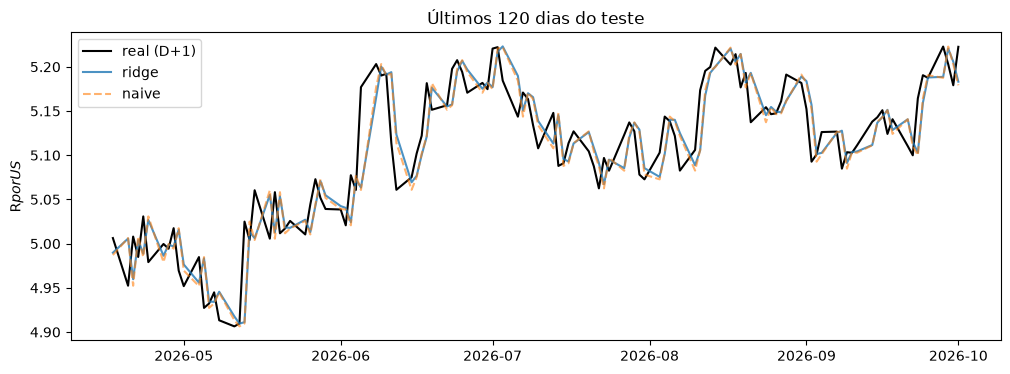

In [11]:
ult = test.index[-120:]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ult, real.loc[ult], label="real (D+1)", color="black")
ax.plot(ult, pred_close.loc[ult], label="ridge", alpha=0.8)
ax.plot(ult, naive_close.loc[ult], label="naive", alpha=0.6, linestyle="--")
ax.set_title("Últimos 120 dias do teste")
ax.set_ylabel(r"R\$ por US\$")
ax.legend()
plt.show()

## Export do artefato

Depois de avaliar no teste, o modelo final é reajustado com todos os dados, para usar as cotações mais recentes. As métricas no `meta.json` são as do teste, com o modelo treinado só no período de treino.

In [12]:
final_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
final_model.fit(feat[FEATURES], feat["target"])

joblib.dump(final_model, MODELS_DIR / "model.joblib")

import sklearn
meta = {
    "ticker": TICKER,
    "model": "StandardScaler + Ridge(alpha=1.0)",
    "target": "log-retorno do dia seguinte",
    "n_lags": N_LAGS,
    "features": FEATURES,
    "closes_esperados": N_LAGS + 1,
    "dados_ate": str(df.index.max().date()),
    "linhas_treino_final": len(feat),
    "metricas_teste": {
        "periodo": f"{test.index.min().date()} -> {test.index.max().date()}",
        "naive_mae": float(resultado.loc["naive", "MAE (R$)"]),
        "ridge_mae": float(resultado.loc["ridge", "MAE (R$)"]),
        "naive_rmse": float(resultado.loc["naive", "RMSE (R$)"]),
        "ridge_rmse": float(resultado.loc["ridge", "RMSE (R$)"]),
        "ridge_acerto_direcao": float(resultado.loc["ridge", "acerto direção"]),
    },
    "sklearn_version": sklearn.__version__,
}
(MODELS_DIR / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "ticker": "BRL=X",
  "model": "StandardScaler + Ridge(alpha=1.0)",
  "target": "log-retorno do dia seguinte",
  "n_lags": 5,
  "features": [
    "r_t-4",
    "r_t-3",
    "r_t-2",
    "r_t-1",
    "r_t"
  ],
  "closes_esperados": 6,
  "dados_ate": "2026-10-02",
  "linhas_treino_final": 3053,
  "metricas_teste": {
    "periodo": "2024-05-24 -> 2026-10-01",
    "naive_mae": 0.03290589442018603,
    "ridge_mae": 0.032598395288289735,
    "naive_rmse": 0.04481985388857022,
    "ridge_rmse": 0.044343419328892686,
    "ridge_acerto_direcao": 0.559016393442623
  },
  "sklearn_version": "1.6.1"
}


## Teste do artefato como a API vai usar

Carrega o `model.joblib` do disco e prevê a partir dos últimos `N_LAGS + 1` fechamentos, que é o que o cliente vai mandar no `POST /predict`.

In [13]:
def prever_de_fechamentos(modelo, closes, n_lags):
    closes = np.asarray(closes, dtype=float)
    if len(closes) != n_lags + 1:
        raise ValueError(f"esperava {n_lags + 1} fechamentos, recebeu {len(closes)}")
    r = np.diff(np.log(closes))                     # n_lags retornos, do mais antigo ao mais recente
    x = pd.DataFrame([r], columns=FEATURES)
    r_prev = modelo.predict(x)[0]
    return float(closes[-1] * np.exp(r_prev))

carregado = joblib.load(MODELS_DIR / "model.joblib")
ultimos = df["close"].iloc[-(N_LAGS + 1):]
print("entrada:", ultimos.round(4).tolist())
print("último fechamento:", round(float(ultimos.iloc[-1]), 4), "em", ultimos.index[-1].date())
print("previsão D+1:", round(prever_de_fechamentos(carregado, ultimos, N_LAGS), 4))

entrada: [5.1905, 5.1875, 5.2229, 5.2029, 5.1791, 5.2226]
último fechamento: 5.2226 em 2026-10-02
previsão D+1: 5.2196
